In [51]:
import os
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib_venn import venn3

In [52]:
FILES = {
    "PAKPV": "feature_importance_PAKPV.txt",
    "PAKOQ": "feature_importance_PAKOQ.txt",
    "PAKOR": "feature_importance_PAKOR.txt",
}

TOP_N = 1000 #this value can be changed

# Feature encoding:
# feature_id = residue1 * 10000 + residue2
PAIR_DIVISOR = 10000

# Residue numbering:
# DIO index 1 corresponds to PDB residue 8
DIO_FIRST_RESIDUE = 1
PDB_FIRST_RESIDUE = 8

# Therefore:
RESIDUE_OFFSET = PDB_FIRST_RESIDUE - DIO_FIRST_RESIDUE
# RESIDUE_OFFSET = 7

OUTPUT_DIR = Path("top1000_feature_comparison")
OUTPUT_DIR.mkdir(exist_ok=True)

SYSTEM_ORDER = ["PAKPV", "PAKOQ", "PAKOR"]

print("DIO residue 1 maps to PDB residue:", 1 + RESIDUE_OFFSET)
print(f"Results will be saved in: {OUTPUT_DIR.resolve()}")

DIO residue 1 maps to PDB residue: 8
Results will be saved in: /home/megha/megha/analyses/autoencoder-allrun/autoencoder_outputs/top1000_feature_comparison


In [53]:
def decode_feature_id(feature_id, divisor=10000):
    """
    Decode an integer feature identifier into two residue numbers.

    Example
    -------
    1630190 -> (163, 190)
    250164  -> (25, 164)
    """
    feature_id = int(feature_id)

    residue1 = feature_id // divisor
    residue2 = feature_id % divisor

    # Canonical ordering ensures that 163-190 and 190-163
    # are treated as the same residue pair.
    residue_low, residue_high = sorted((residue1, residue2))

    return residue_low, residue_high


def load_feature_file(filename, system_name, top_n=5000):
    """
    Read and decode a feature-importance file.

    Feature encoding:
        feature_id = DIO_residue_1 * 10000 + DIO_residue_2

    Residue-number mapping:
        DIO residue 1 -> PDB residue 8
        actual PDB residue = DIO residue + 7
    """

    # Read initially as text so that header rows do not cause errors
    df = pd.read_csv(
        filename,
        sep=r"\s+",
        header=None,
        names=["Feature_ID", "Importance"],
        dtype=str,
        engine="python"
    )

    # Convert to numeric; headers or malformed rows become NaN
    df["Feature_ID"] = pd.to_numeric(
        df["Feature_ID"],
        errors="coerce"
    )

    df["Importance"] = pd.to_numeric(
        df["Importance"],
        errors="coerce"
    )

    invalid_rows = df[
        df["Feature_ID"].isna()
        | df["Importance"].isna()
    ]

    if len(invalid_rows) > 0:
        print(
            f"{system_name}: ignored {len(invalid_rows)} "
            "header or invalid row(s)"
        )

    df = df.dropna(
        subset=["Feature_ID", "Importance"]
    ).copy()

    df["Feature_ID"] = df["Feature_ID"].astype("int64")
    df["Importance"] = df["Importance"].astype(float)

    # Decode the feature ID into DIO residue indices
    decoded_pairs = df["Feature_ID"].apply(decode_feature_id)

    df["DIO_Residue_1"] = decoded_pairs.apply(lambda x: x[0])
    df["DIO_Residue_2"] = decoded_pairs.apply(lambda x: x[1])

    # Map DIO indices to actual PDB residue numbers
    df["Actual_Residue_1"] = (
        df["DIO_Residue_1"] + RESIDUE_OFFSET
    )

    df["Actual_Residue_2"] = (
        df["DIO_Residue_2"] + RESIDUE_OFFSET
    )

    # Labels in DIO numbering
    df["DIO_Feature"] = (
        df["DIO_Residue_1"].astype(str)
        + "-"
        + df["DIO_Residue_2"].astype(str)
    )

    # Labels using actual PDB residue numbers
    df["Actual_Feature"] = (
        df["Actual_Residue_1"].astype(str)
        + "-"
        + df["Actual_Residue_2"].astype(str)
    )

    # Sort by importance
    df = df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    # Remove duplicated DIO residue pairs
    duplicated_count = df.duplicated(
        subset=["DIO_Residue_1", "DIO_Residue_2"]
    ).sum()

    if duplicated_count > 0:
        print(
            f"Warning: {system_name} contains "
            f"{duplicated_count} duplicated residue-pair entries. "
            "The highest-scoring occurrence will be retained."
        )

    df = df.drop_duplicates(
        subset=["DIO_Residue_1", "DIO_Residue_2"],
        keep="first"
    )

    # Retain the top N features
    df = df.head(top_n).copy()

    df["Rank"] = np.arange(1, len(df) + 1)
    df["System"] = system_name

    # Final column order
    df = df[
        [
            "System",
            "Rank",
            "Feature_ID",
            "DIO_Feature",
            "Actual_Feature",
            "DIO_Residue_1",
            "DIO_Residue_2",
            "Actual_Residue_1",
            "Actual_Residue_2",
            "Importance"
        ]
    ]

    return df

In [54]:
feature_data = {}

for system, filename in FILES.items():

    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"File not found for {system}: {filename}"
        )

    feature_data[system] = load_feature_file(
        filename=filename,
        system_name=system,
        top_n=TOP_N
    )

    print(
        f"{system}: retained {len(feature_data[system])} "
        f"unique top-ranked features"
    )

PAKPV: ignored 1 header or invalid row(s)
PAKPV: retained 1000 unique top-ranked features
PAKOQ: ignored 1 header or invalid row(s)
PAKOQ: retained 1000 unique top-ranked features
PAKOR: ignored 1 header or invalid row(s)
PAKOR: retained 1000 unique top-ranked features


In [55]:
feature_data["PAKOQ"].head(10)

,System,Rank,Feature_ID,DIO_Feature,Actual_Feature,DIO_Residue_1,DIO_Residue_2,Actual_Residue_1,Actual_Residue_2,Importance
0,PAKOQ,1,1310162,131-162,138-169,131,162,138,169,16.116044
1,PAKOQ,2,1310163,131-163,138-170,131,163,138,170,15.817779
2,PAKOQ,3,250165,25-165,32-172,25,165,32,172,15.633870
3,PAKOQ,4,1630189,163-189,170-196,163,189,170,196,15.582586
4,PAKOQ,5,250164,25-164,32-171,25,164,32,171,15.482681
5,PAKOQ,6,1290163,129-163,136-170,129,163,136,170,15.454324
6,PAKOQ,7,1290162,129-162,136-169,129,162,136,169,15.405798
7,PAKOQ,8,1630254,163-254,170-261,163,254,170,261,15.342683
8,PAKOQ,9,1300162,130-162,137-169,130,162,137,169,15.139562
9,PAKOQ,10,1710186,171-186,178-193,171,186,178,193,14.937345


In [56]:
for system in SYSTEM_ORDER:
    output_file = OUTPUT_DIR / f"{system}_top{TOP_N}_decoded_features.csv"
    feature_data[system].to_csv(output_file, index=False)

print("Decoded top-feature tables saved.")

Decoded top-feature tables saved.


In [57]:
feature_sets = {}

for system in SYSTEM_ORDER:
    feature_sets[system] = set(
        zip(
            feature_data[system]["DIO_Residue_1"],
            feature_data[system]["DIO_Residue_2"]
        )
    )

for system in SYSTEM_ORDER:
    print(
        system,
        "number of features =",
        len(feature_sets[system])
    )

PAKPV number of features = 1000
PAKOQ number of features = 1000
PAKOR number of features = 1000


In [58]:
features_PAKPV = feature_sets["PAKPV"]
features_PAKOQ = feature_sets["PAKOQ"]
features_PAKOR = feature_sets["PAKOR"]

# Features common to all three systems
common_features_all = (
    features_PAKPV
    & features_PAKOQ
    & features_PAKOR
)

# Pairwise intersections, including features that may also be in the third set
common_PAKPV_PAKOQ = features_PAKPV & features_PAKOQ
common_PAKPV_PAKOR = features_PAKPV & features_PAKOR
common_PAKOQ_PAKOR = features_PAKOQ & features_PAKOR

# Features exclusive to only one system
unique_PAKPV = features_PAKPV - features_PAKOQ - features_PAKOR
unique_PAKOQ = features_PAKOQ - features_PAKPV - features_PAKOR
unique_PAKOR = features_PAKOR - features_PAKPV - features_PAKOQ

# Features shared by exactly two systems
only_PAKPV_PAKOQ = (
    features_PAKPV
    & features_PAKOQ
) - features_PAKOR

only_PAKPV_PAKOR = (
    features_PAKPV
    & features_PAKOR
) - features_PAKOQ

only_PAKOQ_PAKOR = (
    features_PAKOQ
    & features_PAKOR
) - features_PAKPV

print("Common exact features in all three systems:", len(common_features_all))
print()
print("Common between PAKPV and PAKOQ:", len(common_PAKPV_PAKOQ))
print("Common between PAKPV and PAKOR:", len(common_PAKPV_PAKOR))
print("Common between PAKOQ and PAKOR:", len(common_PAKOQ_PAKOR))
print()
print("Unique to PAKPV:", len(unique_PAKPV))
print("Unique to PAKOQ:", len(unique_PAKOQ))
print("Unique to PAKOR:", len(unique_PAKOR))

Common exact features in all three systems: 281

Common between PAKPV and PAKOQ: 292
Common between PAKPV and PAKOR: 314
Common between PAKOQ and PAKOR: 875

Unique to PAKPV: 675
Unique to PAKOQ: 114
Unique to PAKOR: 92


In [59]:
def prepare_feature_system_table(df, system):
    temp = df[
        [
            "DIO_Residue_1",
            "DIO_Residue_2",
            "Actual_Residue_1",
            "Actual_Residue_2",
            "DIO_Feature",
            "Actual_Feature",
            "Importance",
            "Rank"
        ]
    ].copy()

    temp = temp.rename(
        columns={
            "Importance": f"Importance_{system}",
            "Rank": f"Rank_{system}"
        }
    )

    return temp

In [60]:
merge_columns = [
    "DIO_Residue_1",
    "DIO_Residue_2",
    "Actual_Residue_1",
    "Actual_Residue_2",
    "DIO_Feature",
    "Actual_Feature"
]

common_feature_df = prepare_feature_system_table(
    feature_data["PAKPV"], "PAKPV"
)

common_feature_df = common_feature_df.merge(
    prepare_feature_system_table(feature_data["PAKOQ"], "PAKOQ"),
    on=merge_columns,
    how="inner"
)

common_feature_df = common_feature_df.merge(
    prepare_feature_system_table(feature_data["PAKOR"], "PAKOR"),
    on=merge_columns,
    how="inner"
)

# Mean importance across all three systems
common_feature_df["Mean_Importance"] = common_feature_df[
    [
        "Importance_PAKPV",
        "Importance_PAKOQ",
        "Importance_PAKOR"
    ]
].mean(axis=1)

# Importance changes
common_feature_df["Change_PAKOQ_minus_PAKPV"] = (
    common_feature_df["Importance_PAKOQ"]
    - common_feature_df["Importance_PAKPV"]
)

common_feature_df["Change_PAKOR_minus_PAKOQ"] = (
    common_feature_df["Importance_PAKOR"]
    - common_feature_df["Importance_PAKOQ"]
)

common_feature_df["Overall_change_PAKOR_minus_PAKPV"] = (
    common_feature_df["Importance_PAKOR"]
    - common_feature_df["Importance_PAKPV"]
)

common_feature_df = common_feature_df.sort_values(
    "Mean_Importance",
    ascending=False
).reset_index(drop=True)

common_feature_df.to_csv(
    OUTPUT_DIR / f"common_features_all_three_top{TOP_N}.csv",
    index=False
)

print("Number of features common to all systems:", len(common_feature_df))

common_feature_df.head(20)

Number of features common to all systems: 281


,DIO_Residue_1,DIO_Residue_2,Actual_Residue_1,Actual_Residue_2,DIO_Feature,Actual_Feature,Importance_PAKPV,Rank_PAKPV,Importance_PAKOQ,Rank_PAKOQ,Importance_PAKOR,Rank_PAKOR,Mean_Importance,Change_PAKOQ_minus_PAKPV,Change_PAKOR_minus_PAKOQ,Overall_change_PAKOR_minus_PAKPV
0,131,162,138,169,131-162,138-169,6.039798,77,16.116044,1,16.731857,1,12.962567,10.076246,0.615813,10.692059
1,131,163,138,170,131-163,138-170,6.138917,59,15.817779,2,15.861974,3,12.606224,9.678861,0.044195,9.723057
2,129,162,136,169,129-162,136-169,5.976183,89,15.405798,7,16.003412,2,12.461798,9.429615,0.597615,10.027229
3,129,163,136,170,129-163,136-170,6.073921,70,15.454324,6,15.460283,5,12.329509,9.380403,0.005959,9.386362
4,163,189,170,196,163-189,170-196,6.246477,44,15.582586,4,15.095152,9,12.308072,9.336109,-0.487434,8.848675
5,130,162,137,169,130-162,137-169,6.212231,47,15.139562,9,15.523287,4,12.291693,8.927331,0.383725,9.311055
6,163,254,170,261,163-254,170-261,6.310061,38,15.342683,8,14.834635,13,12.162459,9.032622,-0.508048,8.524574
7,25,164,32,171,25-164,32-171,5.462654,195,15.482681,5,15.144456,7,12.029931,10.020027,-0.338225,9.681802
8,128,163,135,170,128-163,135-170,6.033379,80,14.630681,12,14.659734,16,11.774598,8.597301,0.029053,8.626355
9,163,190,170,197,163-190,170-197,5.965166,93,14.717706,11,14.545960,17,11.742944,8.752540,-0.171746,8.580794


In [61]:
def save_pair_set(pair_set, filename):
    pair_df = pd.DataFrame(
        sorted(pair_set),
        columns=["DIO_Residue_1", "DIO_Residue_2"]
    )

    pair_df["Actual_Residue_1"] = (
        pair_df["DIO_Residue_1"] + RESIDUE_OFFSET
    )

    pair_df["Actual_Residue_2"] = (
        pair_df["DIO_Residue_2"] + RESIDUE_OFFSET
    )

    pair_df["DIO_Feature"] = (
        pair_df["DIO_Residue_1"].astype(str)
        + "-"
        + pair_df["DIO_Residue_2"].astype(str)
    )

    pair_df["Actual_Feature"] = (
        pair_df["Actual_Residue_1"].astype(str)
        + "-"
        + pair_df["Actual_Residue_2"].astype(str)
    )

    pair_df = pair_df[
        [
            "DIO_Feature",
            "Actual_Feature",
            "DIO_Residue_1",
            "DIO_Residue_2",
            "Actual_Residue_1",
            "Actual_Residue_2"
        ]
    ]

    pair_df.to_csv(filename, index=False)

In [62]:
save_pair_set(
    common_features_all,
    OUTPUT_DIR / "features_common_to_all_three.csv"
)

save_pair_set(
    unique_PAKPV,
    OUTPUT_DIR / "features_unique_to_PAKPV.csv"
)

save_pair_set(
    unique_PAKOQ,
    OUTPUT_DIR / "features_unique_to_PAKOQ.csv"
)

save_pair_set(
    unique_PAKOR,
    OUTPUT_DIR / "features_unique_to_PAKOR.csv"
)

save_pair_set(
    only_PAKPV_PAKOQ,
    OUTPUT_DIR / "features_shared_only_PAKPV_PAKOQ.csv"
)

save_pair_set(
    only_PAKPV_PAKOR,
    OUTPUT_DIR / "features_shared_only_PAKPV_PAKOR.csv"
)

save_pair_set(
    only_PAKOQ_PAKOR,
    OUTPUT_DIR / "features_shared_only_PAKOQ_PAKOR.csv"
)

print("Feature-overlap lists saved.")

Feature-overlap lists saved.


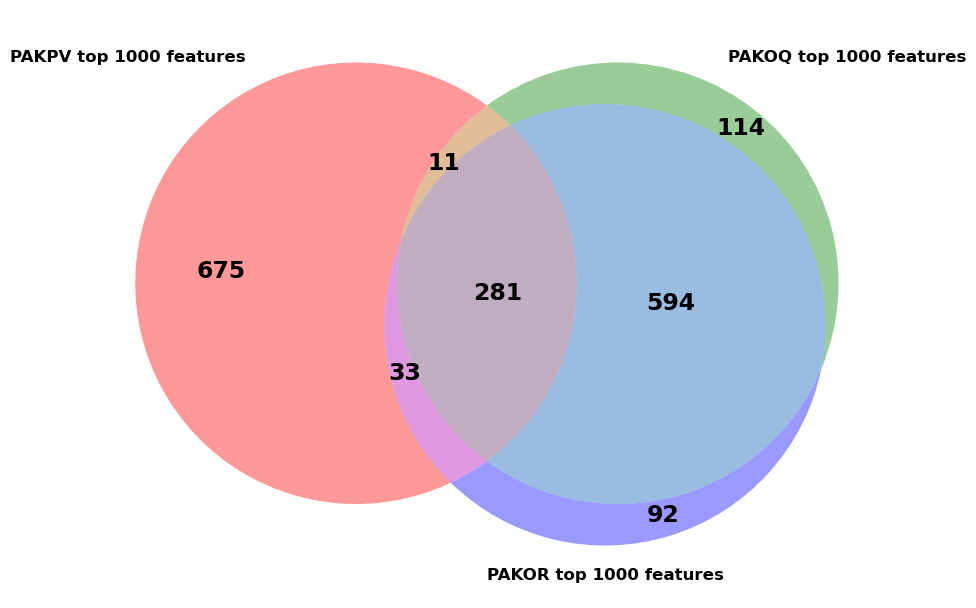

In [63]:
plt.figure(figsize=(10, 9))

v = venn3(
    [
        features_PAKPV,
        features_PAKOQ,
        features_PAKOR
    ],
    set_labels=(
        f"PAKPV top {TOP_N} features",
        f"PAKOQ top {TOP_N} features",
        f"PAKOR top {TOP_N} features"
    )
)

for label in v.set_labels:
    if label is not None:
        label.set_fontsize(12)
        label.set_fontweight("bold")

for label in v.subset_labels:
    if label is not None:
        label.set_fontsize(17)
        label.set_fontweight("bold")

plt.axis("off")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / f"venn_exact_features_top{TOP_N}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [64]:
#part2-common residues#

dio_residue_sets = {}
actual_residue_sets = {}

for system in SYSTEM_ORDER:
    df = feature_data[system]

    dio_residues = (
        set(df["DIO_Residue_1"])
        | set(df["DIO_Residue_2"])
    )

    actual_residues = (
        set(df["Actual_Residue_1"])
        | set(df["Actual_Residue_2"])
    )

    dio_residue_sets[system] = dio_residues
    actual_residue_sets[system] = actual_residues

    print(
        f"{system}: {len(dio_residues)} unique residues "
        f"occur in the top {TOP_N} features"
    )

PAKPV: 267 unique residues occur in the top 1000 features
PAKOQ: 218 unique residues occur in the top 1000 features
PAKOR: 219 unique residues occur in the top 1000 features


In [65]:
residues_PAKPV = actual_residue_sets["PAKPV"]
residues_PAKOQ = actual_residue_sets["PAKOQ"]
residues_PAKOR = actual_residue_sets["PAKOR"]

common_residues_all = (
    residues_PAKPV
    & residues_PAKOQ
    & residues_PAKOR
)

unique_residues_PAKPV = (
    residues_PAKPV
    - residues_PAKOQ
    - residues_PAKOR
)

unique_residues_PAKOQ = (
    residues_PAKOQ
    - residues_PAKPV
    - residues_PAKOR
)

unique_residues_PAKOR = (
    residues_PAKOR
    - residues_PAKPV
    - residues_PAKOQ
)

residues_only_PAKPV_PAKOQ = (
    residues_PAKPV
    & residues_PAKOQ
) - residues_PAKOR

residues_only_PAKPV_PAKOR = (
    residues_PAKPV
    & residues_PAKOR
) - residues_PAKOQ

residues_only_PAKOQ_PAKOR = (
    residues_PAKOQ
    & residues_PAKOR
) - residues_PAKPV

print("Residues common to all three:", len(common_residues_all))
print()
print("Residues unique to PAKPV:", len(unique_residues_PAKPV))
print("Residues unique to PAKOQ:", len(unique_residues_PAKOQ))
print("Residues unique to PAKOR:", len(unique_residues_PAKOR))

Residues common to all three: 198

Residues unique to PAKPV: 54
Residues unique to PAKOQ: 0
Residues unique to PAKOR: 0


In [66]:
print("Residues common to all three systems:")
print(sorted(common_residues_all))

Residues common to all three systems:
[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 47, 49, 51, 52, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 102, 104, 107, 121, 122, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 147, 158, 159, 160, 161, 162, 163, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 204, 205, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 285, 286, 289, 290, 291, 292, 293, 294, 295, 296]


In [67]:
residue_overlap_dict = {
    "Common_all_three": sorted(common_residues_all),
    "Unique_PAKPV": sorted(unique_residues_PAKPV),
    "Unique_PAKOQ": sorted(unique_residues_PAKOQ),
    "Unique_PAKOR": sorted(unique_residues_PAKOR),
    "Shared_only_PAKPV_PAKOQ": sorted(residues_only_PAKPV_PAKOQ),
    "Shared_only_PAKPV_PAKOR": sorted(residues_only_PAKPV_PAKOR),
    "Shared_only_PAKOQ_PAKOR": sorted(residues_only_PAKOQ_PAKOR),
}

for category, residues in residue_overlap_dict.items():
    pd.DataFrame(
        {"Residue": residues}
    ).to_csv(
        OUTPUT_DIR / f"{category}.csv",
        index=False
    )

print("Residue-overlap lists saved.")

Residue-overlap lists saved.


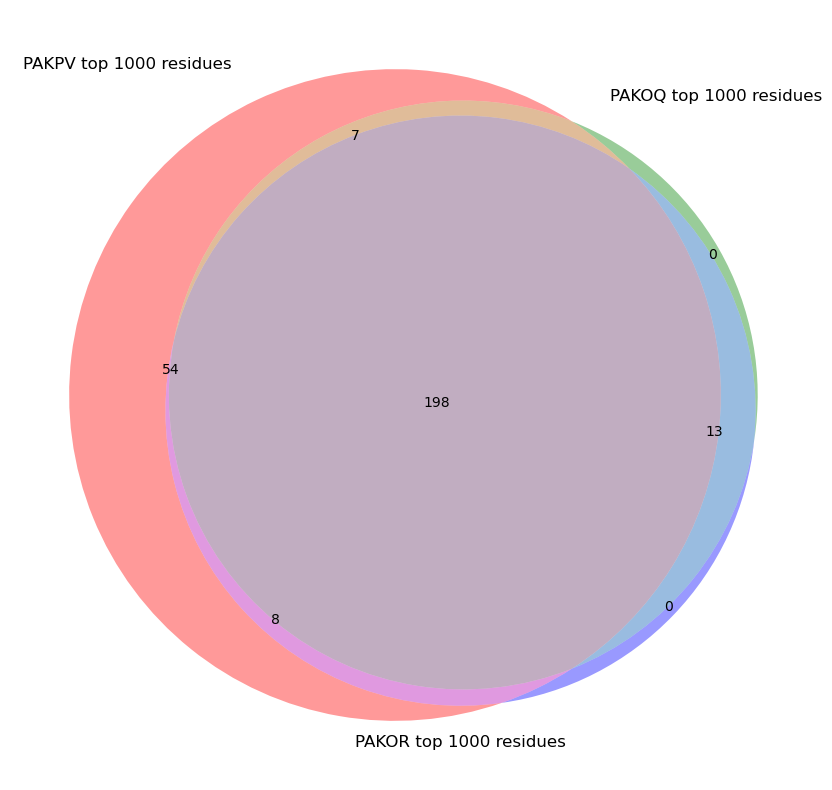

In [68]:
plt.figure(figsize=(9, 8))

venn3(
    [
        residues_PAKPV,
        residues_PAKOQ,
        residues_PAKOR
    ],
    set_labels=(
        f"PAKPV top {TOP_N} residues",
        f"PAKOQ top {TOP_N} residues",
        f"PAKOR top {TOP_N} residues"
    )
)
for label in v.set_labels:
    if label is not None:
        label.set_fontsize(12)
        label.set_fontweight("bold")

for label in v.subset_labels:
    if label is not None:
        label.set_fontsize(17)
        label.set_fontweight("bold")

plt.axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / f"venn_residues_top{TOP_N}.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [69]:
residue_overlap_dict = {
    "Common_all_three": sorted(common_residues_all),
    "Unique_PAKPV": sorted(unique_residues_PAKPV),
    "Unique_PAKOQ": sorted(unique_residues_PAKOQ),
    "Unique_PAKOR": sorted(unique_residues_PAKOR),
    "Shared_only_PAKPV_PAKOQ": sorted(residues_only_PAKPV_PAKOQ),
    "Shared_only_PAKPV_PAKOR": sorted(residues_only_PAKPV_PAKOR),
    "Shared_only_PAKOQ_PAKOR": sorted(residues_only_PAKOQ_PAKOR),
}

for category, actual_residues in residue_overlap_dict.items():

    residue_table = pd.DataFrame({
        "Actual_Residue": actual_residues
    })

    residue_table["DIO_Residue_Index"] = (
        residue_table["Actual_Residue"] - RESIDUE_OFFSET
    )

    residue_table = residue_table[
        ["DIO_Residue_Index", "Actual_Residue"]
    ]

    residue_table.to_csv(
        OUTPUT_DIR / f"{category}.csv",
        index=False
    )

print("Residue-overlap lists saved with both numbering systems.")

Residue-overlap lists saved with both numbering systems.


In [70]:
def calculate_residue_statistics(df, system):
    """
    Calculate residue frequency and importance scores.

    Statistics are accumulated using DIO residue indices.
    A separate actual PDB residue-number column is then added.

    Mapping:
        DIO index 1 -> PDB residue 8
        Actual residue = DIO index + 7
    """

    frequency = Counter()
    full_importance = Counter()
    half_importance = Counter()

    for row in df.itertuples(index=False):

        residue1 = row.DIO_Residue_1
        residue2 = row.DIO_Residue_2
        importance_value = row.Importance

        # Number of selected features containing each residue
        frequency[residue1] += 1
        frequency[residue2] += 1

        # Full feature score assigned to each residue
        full_importance[residue1] += importance_value
        full_importance[residue2] += importance_value

        # Half feature score assigned to each residue
        half_importance[residue1] += importance_value / 2.0
        half_importance[residue2] += importance_value / 2.0

    all_dio_residues = sorted(frequency.keys())

    result = pd.DataFrame({
        "DIO_Residue_Index": all_dio_residues,

        "Actual_Residue": [
            residue + RESIDUE_OFFSET
            for residue in all_dio_residues
        ],

        f"Frequency_{system}": [
            frequency[residue]
            for residue in all_dio_residues
        ],

        f"Importance_Sum_{system}": [
            full_importance[residue]
            for residue in all_dio_residues
        ],

        f"Half_Importance_Score_{system}": [
            half_importance[residue]
            for residue in all_dio_residues
        ]
    })

    return result

In [71]:
residue_statistics = {}

for system in SYSTEM_ORDER:
    residue_statistics[system] = calculate_residue_statistics(
        feature_data[system],
        system
    )

    residue_statistics[system].to_csv(
        OUTPUT_DIR / f"residue_statistics_{system}_top{TOP_N}.csv",
        index=False
    )

residue_statistics["PAKPV"].head()

,DIO_Residue_Index,Actual_Residue,Frequency_PAKPV,Importance_Sum_PAKPV,Half_Importance_Score_PAKPV
0,1,8,2,9.398761,4.699381
1,2,9,4,18.000698,9.000349
2,3,10,5,23.122250,11.561125
3,4,11,3,14.457604,7.228802
4,5,12,3,13.978695,6.989348


In [72]:
residue_comparison = residue_statistics["PAKPV"].copy()

for system in ["PAKOQ", "PAKOR"]:
    residue_comparison = residue_comparison.merge(
        residue_statistics[system],
       on=[
            "DIO_Residue_Index",
            "Actual_Residue"
        ],
        how="outer"
    )

residue_comparison = residue_comparison.fillna(0)

# Convert frequency values back to integers
for system in SYSTEM_ORDER:
    residue_comparison[f"Frequency_{system}"] = (
        residue_comparison[f"Frequency_{system}"].astype(int)
    )

# Whether the residue is present in the top 1000 features
for system in SYSTEM_ORDER:
    residue_comparison[f"Present_{system}"] = (
        residue_comparison[f"Frequency_{system}"] > 0
    )

residue_comparison.head()

,DIO_Residue_Index,Actual_Residue,Frequency_PAKPV,Importance_Sum_PAKPV,Half_Importance_Score_PAKPV,Frequency_PAKOQ,Importance_Sum_PAKOQ,Half_Importance_Score_PAKOQ,Frequency_PAKOR,Importance_Sum_PAKOR,Half_Importance_Score_PAKOR,Present_PAKPV,Present_PAKOQ,Present_PAKOR
0,1,8,2,9.398761,4.699381,2,15.694558,7.847279,4,34.041529,17.020764,True,True,True
1,2,9,4,18.000698,9.000349,3,24.831064,12.415532,4,33.903941,16.951970,True,True,True
2,3,10,5,23.122250,11.561125,3,25.608218,12.804109,4,34.711199,17.355599,True,True,True
3,4,11,3,14.457604,7.228802,3,24.037045,12.018523,3,25.335467,12.667733,True,True,True
4,5,12,3,13.978695,6.989348,2,16.184349,8.092174,2,16.845298,8.422649,True,True,True


In [73]:
residue_comparison["Change_PAKOQ_minus_PAKPV"] = (
    residue_comparison["Frequency_PAKOQ"]
    - residue_comparison["Frequency_PAKPV"]
)

residue_comparison["Change_PAKOR_minus_PAKOQ"] = (
    residue_comparison["Frequency_PAKOR"]
    - residue_comparison["Frequency_PAKOQ"]
)

residue_comparison["Overall_change_PAKOR_minus_PAKPV"] = (
    residue_comparison["Frequency_PAKOR"]
    - residue_comparison["Frequency_PAKPV"]
)

residue_comparison["Total_Frequency"] = (
    residue_comparison[
        [
            "Frequency_PAKPV",
            "Frequency_PAKOQ",
            "Frequency_PAKOR"
        ]
    ].sum(axis=1)
)

In [74]:
common_residue_comparison = residue_comparison[
    residue_comparison["Actual_Residue"].isin(
        common_residues_all
    )
].copy()

common_residue_comparison = common_residue_comparison.sort_values(
    "Total_Frequency",
    ascending=False
).reset_index(drop=True)

common_residue_comparison.to_csv(
    OUTPUT_DIR / f"common_residue_frequency_comparison_top{TOP_N}.csv",
    index=False
)

common_residue_comparison.head(30)

,DIO_Residue_Index,Actual_Residue,Frequency_PAKPV,Importance_Sum_PAKPV,Half_Importance_Score_PAKPV,Frequency_PAKOQ,Importance_Sum_PAKOQ,Half_Importance_Score_PAKOQ,Frequency_PAKOR,Importance_Sum_PAKOR,Half_Importance_Score_PAKOR,Present_PAKPV,Present_PAKOQ,Present_PAKOR,Change_PAKOQ_minus_PAKPV,Change_PAKOR_minus_PAKOQ,Overall_change_PAKOR_minus_PAKPV,Total_Frequency
0,162,169,159,808.888091,404.444045,81,785.292530,392.646265,84,849.957572,424.978786,True,True,True,-78,3,-75,324
1,163,170,106,549.904314,274.952157,96,963.154892,481.577446,90,906.932765,453.466383,True,True,True,-10,-6,-16,292
2,164,171,22,101.007692,50.503846,89,825.648283,412.824142,93,873.680196,436.840098,True,True,True,67,4,71,204
3,173,180,10,53.365057,26.682529,99,861.653169,430.826584,86,731.278762,365.639381,True,True,True,89,-13,76,195
4,165,172,4,18.696176,9.348088,93,831.380982,415.690491,89,790.255504,395.127752,True,True,True,89,-4,85,186
5,169,176,51,252.826485,126.413243,64,547.588250,273.794125,68,597.244598,298.622299,True,True,True,13,4,17,183
6,161,168,70,330.585891,165.292946,59,528.909777,264.454889,53,485.201555,242.600778,True,True,True,-11,-6,-17,182
7,166,173,29,129.516631,64.758315,71,645.167619,322.583809,75,716.351410,358.175705,True,True,True,42,4,46,175
8,167,174,28,131.318328,65.659164,70,642.341017,321.170508,75,720.829254,360.414627,True,True,True,42,5,47,173
9,168,175,36,176.296483,88.148241,52,441.727598,220.863799,68,585.658240,292.829120,True,True,True,16,16,32,156


In [75]:
def classify_frequency_trend(row):

    PV = row["Frequency_PAKPV"]
    OQ = row["Frequency_PAKOQ"]
    OR = row["Frequency_PAKOR"]

    if PV < OQ < OR:
        return "Strictly increased"

    elif PV > OQ > OR:
        return "Strictly decreased"

    elif PV <= OQ <= OR and PV < OR:
        return "Generally increased"

    elif PV >= OQ >= OR and PV > OR:
        return "Generally decreased"

    elif PV == OQ == OR:
        return "Unchanged"

    elif OR > PV:
        return "Fluctuated; overall increased"

    elif OR < PV:
        return "Fluctuated; overall decreased"

    else:
        return "Fluctuated; no overall change"

In [76]:
residue_comparison["Frequency_Trend"] = residue_comparison.apply(
    classify_frequency_trend,
    axis=1
)

residue_comparison = residue_comparison.sort_values(
    ["Total_Frequency", "Actual_Residue"],
    ascending=[False, True]
).reset_index(drop=True)

residue_comparison.to_csv(
    OUTPUT_DIR / f"all_residue_frequency_comparison_top{TOP_N}.csv",
    index=False
)

residue_comparison.head(20)

,DIO_Residue_Index,Actual_Residue,Frequency_PAKPV,Importance_Sum_PAKPV,Half_Importance_Score_PAKPV,Frequency_PAKOQ,Importance_Sum_PAKOQ,Half_Importance_Score_PAKOQ,Frequency_PAKOR,Importance_Sum_PAKOR,Half_Importance_Score_PAKOR,Present_PAKPV,Present_PAKOQ,Present_PAKOR,Change_PAKOQ_minus_PAKPV,Change_PAKOR_minus_PAKOQ,Overall_change_PAKOR_minus_PAKPV,Total_Frequency,Frequency_Trend
0,162,169,159,808.888091,404.444045,81,785.292530,392.646265,84,849.957572,424.978786,True,True,True,-78,3,-75,324,Fluctuated; overall decreased
1,163,170,106,549.904314,274.952157,96,963.154892,481.577446,90,906.932765,453.466383,True,True,True,-10,-6,-16,292,Strictly decreased
2,164,171,22,101.007692,50.503846,89,825.648283,412.824142,93,873.680196,436.840098,True,True,True,67,4,71,204,Strictly increased
3,173,180,10,53.365057,26.682529,99,861.653169,430.826584,86,731.278762,365.639381,True,True,True,89,-13,76,195,Fluctuated; overall increased
4,165,172,4,18.696176,9.348088,93,831.380982,415.690491,89,790.255504,395.127752,True,True,True,89,-4,85,186,Fluctuated; overall increased
5,169,176,51,252.826485,126.413243,64,547.588250,273.794125,68,597.244598,298.622299,True,True,True,13,4,17,183,Strictly increased
6,161,168,70,330.585891,165.292946,59,528.909777,264.454889,53,485.201555,242.600778,True,True,True,-11,-6,-17,182,Strictly decreased
7,166,173,29,129.516631,64.758315,71,645.167619,322.583809,75,716.351410,358.175705,True,True,True,42,4,46,175,Strictly increased
8,167,174,28,131.318328,65.659164,70,642.341017,321.170508,75,720.829254,360.414627,True,True,True,42,5,47,173,Strictly increased
9,168,175,36,176.296483,88.148241,52,441.727598,220.863799,68,585.658240,292.829120,True,True,True,16,16,32,156,Strictly increased


In [77]:
common_residue_comparison = residue_comparison[
    residue_comparison["Actual_Residue"].isin(common_residues_all)
].copy()

common_residue_comparison = common_residue_comparison.sort_values(
    "Total_Frequency",
    ascending=False
).reset_index(drop=True)

common_residue_comparison.to_csv(
    OUTPUT_DIR / f"common_residue_frequency_comparison_top{TOP_N}.csv",
    index=False
)

common_residue_comparison.head(30)

,DIO_Residue_Index,Actual_Residue,Frequency_PAKPV,Importance_Sum_PAKPV,Half_Importance_Score_PAKPV,Frequency_PAKOQ,Importance_Sum_PAKOQ,Half_Importance_Score_PAKOQ,Frequency_PAKOR,Importance_Sum_PAKOR,Half_Importance_Score_PAKOR,Present_PAKPV,Present_PAKOQ,Present_PAKOR,Change_PAKOQ_minus_PAKPV,Change_PAKOR_minus_PAKOQ,Overall_change_PAKOR_minus_PAKPV,Total_Frequency,Frequency_Trend
0,162,169,159,808.888091,404.444045,81,785.292530,392.646265,84,849.957572,424.978786,True,True,True,-78,3,-75,324,Fluctuated; overall decreased
1,163,170,106,549.904314,274.952157,96,963.154892,481.577446,90,906.932765,453.466383,True,True,True,-10,-6,-16,292,Strictly decreased
2,164,171,22,101.007692,50.503846,89,825.648283,412.824142,93,873.680196,436.840098,True,True,True,67,4,71,204,Strictly increased
3,173,180,10,53.365057,26.682529,99,861.653169,430.826584,86,731.278762,365.639381,True,True,True,89,-13,76,195,Fluctuated; overall increased
4,165,172,4,18.696176,9.348088,93,831.380982,415.690491,89,790.255504,395.127752,True,True,True,89,-4,85,186,Fluctuated; overall increased
5,169,176,51,252.826485,126.413243,64,547.588250,273.794125,68,597.244598,298.622299,True,True,True,13,4,17,183,Strictly increased
6,161,168,70,330.585891,165.292946,59,528.909777,264.454889,53,485.201555,242.600778,True,True,True,-11,-6,-17,182,Strictly decreased
7,166,173,29,129.516631,64.758315,71,645.167619,322.583809,75,716.351410,358.175705,True,True,True,42,4,46,175,Strictly increased
8,167,174,28,131.318328,65.659164,70,642.341017,321.170508,75,720.829254,360.414627,True,True,True,42,5,47,173,Strictly increased
9,168,175,36,176.296483,88.148241,52,441.727598,220.863799,68,585.658240,292.829120,True,True,True,16,16,32,156,Strictly increased


In [78]:
strictly_increased = common_residue_comparison[
    common_residue_comparison["Frequency_Trend"]
    == "Strictly increased"
]

strictly_decreased = common_residue_comparison[
    common_residue_comparison["Frequency_Trend"]
    == "Strictly decreased"
]

generally_increased = common_residue_comparison[
    common_residue_comparison["Frequency_Trend"].isin(
        [
            "Strictly increased",
            "Generally increased",
            "Fluctuated; overall increased"
        ]
    )
]

generally_decreased = common_residue_comparison[
    common_residue_comparison["Frequency_Trend"].isin(
        [
            "Strictly decreased",
            "Generally decreased",
            "Fluctuated; overall decreased"
        ]
    )
]

print("Strictly increased residues:")
print(strictly_increased["Actual_Residue"].tolist())

print("\nStrictly decreased residues:")
print(strictly_decreased["Actual_Residue"].tolist())

print("\nNumber with an overall increase:", len(generally_increased))
print("Number with an overall decrease:", len(generally_decreased))

Strictly increased residues:
[171, 176, 173, 174, 175, 178, 137, 139, 136, 135, 194, 72, 198, 133, 263, 75, 76, 129, 289, 107, 104]

Strictly decreased residues:
[170, 168, 167, 294, 32, 192, 31, 188, 189, 44, 187, 45, 165, 17, 19, 18, 16]

Number with an overall increase: 103
Number with an overall decrease: 62


In [79]:
strictly_increased.to_csv(
    OUTPUT_DIR / "common_residues_strictly_increased.csv",
    index=False
)

strictly_decreased.to_csv(
    OUTPUT_DIR / "common_residues_strictly_decreased.csv",
    index=False
)

generally_increased.to_csv(
    OUTPUT_DIR / "common_residues_overall_increased.csv",
    index=False
)

generally_decreased.to_csv(
    OUTPUT_DIR / "common_residues_overall_decreased.csv",
    index=False
)

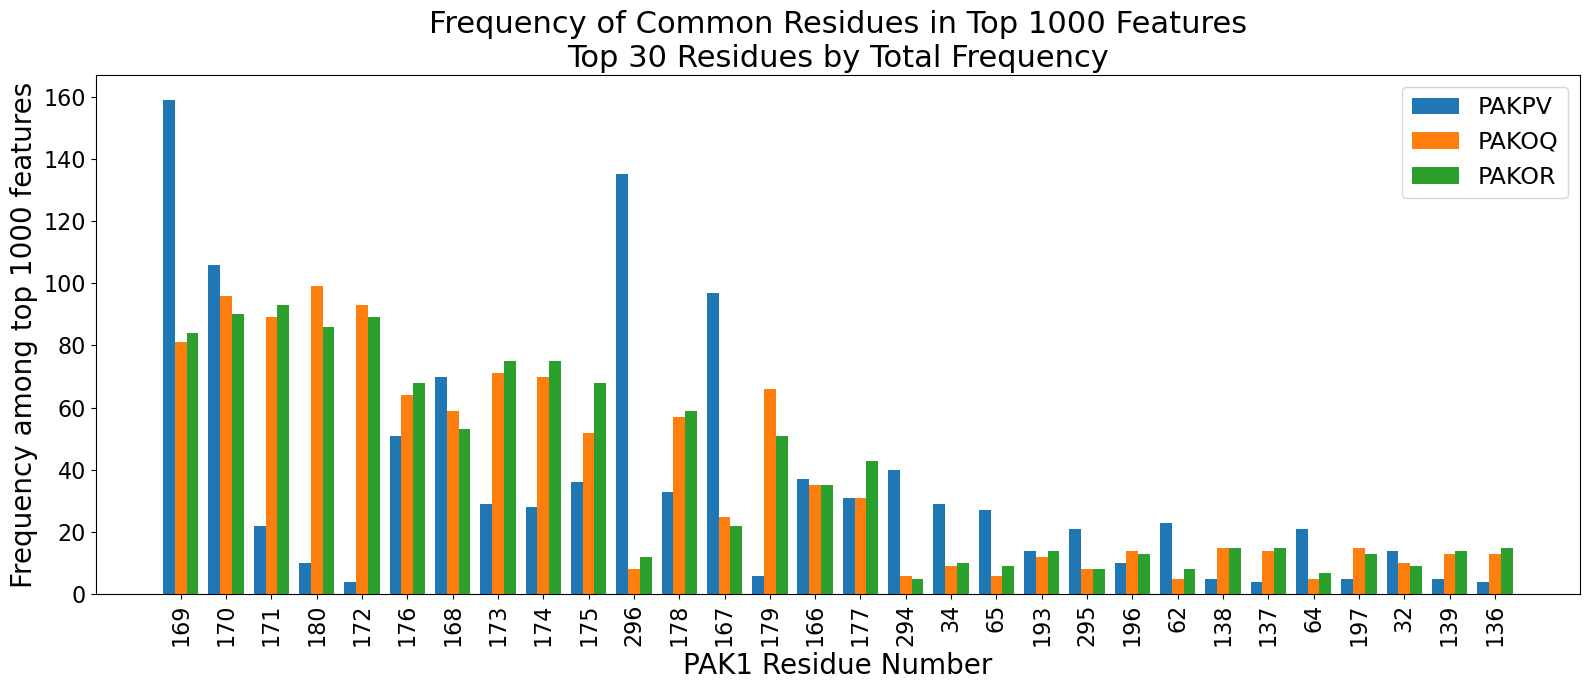

In [80]:
TOP_RESIDUES_TO_PLOT = 30

# ============================================================
# FONT SIZE SETTINGS
# ============================================================
TITLE_SIZE = 22
AXIS_LABEL_SIZE = 20
X_TICK_SIZE = 16
Y_TICK_SIZE = 16
LEGEND_SIZE = 17

plot_df = common_residue_comparison.head(
    TOP_RESIDUES_TO_PLOT
).copy()

x = np.arange(len(plot_df))
bar_width = 0.26

plt.figure(figsize=(16, 7))

plt.bar(
    x - bar_width,
    plot_df["Frequency_PAKPV"],
    width=bar_width,
    label="PAKPV"
)

plt.bar(
    x,
    plot_df["Frequency_PAKOQ"],
    width=bar_width,
    label="PAKOQ"
)

plt.bar(
    x + bar_width,
    plot_df["Frequency_PAKOR"],
    width=bar_width,
    label="PAKOR"
)

# X-axis residue numbers
plt.xticks(
    x,
    plot_df["Actual_Residue"],
    rotation=90,
    fontsize=X_TICK_SIZE
)

# Y-axis numerical values
plt.yticks(
    fontsize=Y_TICK_SIZE
)

# X and Y axis labels
plt.xlabel(
    "PAK1 Residue Number",
    fontsize=AXIS_LABEL_SIZE
)

plt.ylabel(
    f"Frequency among top {TOP_N} features",
    fontsize=AXIS_LABEL_SIZE
)

# Plot title
plt.title(
    f"Frequency of Common Residues in Top {TOP_N} Features\n"
    f"Top {TOP_RESIDUES_TO_PLOT} Residues by Total Frequency",
    fontsize=TITLE_SIZE
)

# Legend
plt.legend(
    fontsize=LEGEND_SIZE
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "common_top30_residue_frequency_grouped_bar.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

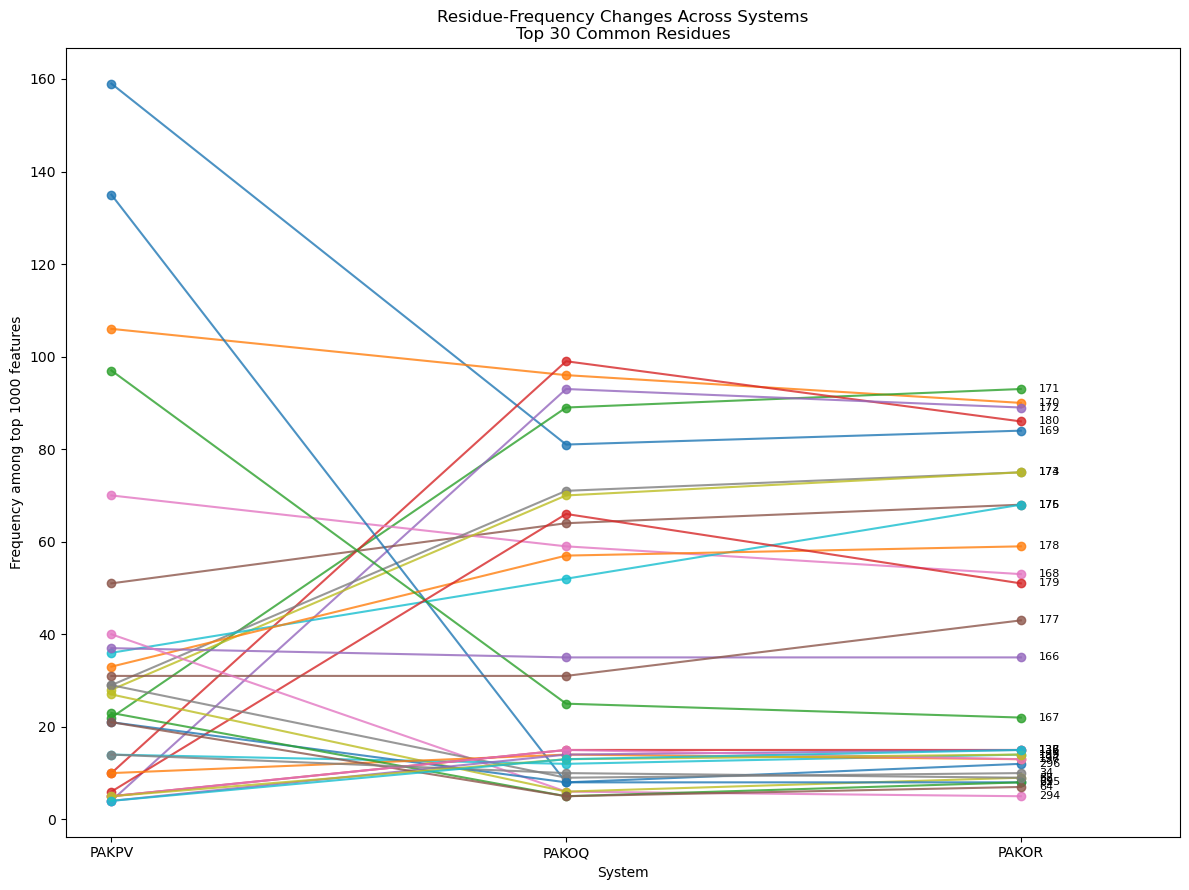

In [81]:
TOP_RESIDUES_TO_PLOT = 30

# ============================================================
# FONT SIZE SETTINGS
# ============================================================
TITLE_SIZE = 22
AXIS_LABEL_SIZE = 20
X_TICK_SIZE = 16
Y_TICK_SIZE = 16
LEGEND_SIZE = 17

plot_df = common_residue_comparison.head(
    TOP_RESIDUES_TO_PLOT
).copy()

plt.figure(figsize=(12, 9))

x_positions = np.arange(len(SYSTEM_ORDER))

for row in plot_df.itertuples(index=False):

    frequencies = [
        row.Frequency_PAKPV,
        row.Frequency_PAKOQ,
        row.Frequency_PAKOR
    ]

    plt.plot(
        x_positions,
        frequencies,
        marker="o",
        linewidth=1.5,
        alpha=0.8
    )

    # Label each residue at the final system
    plt.text(
        x_positions[-1] + 0.04,
        frequencies[-1],
        str(row.Actual_Residue),
        fontsize=8,
        va="center"
    )

plt.xticks(x_positions, SYSTEM_ORDER)
plt.xlabel("System")
plt.ylabel(f"Frequency among top {TOP_N} features")

plt.title(
    f"Residue-Frequency Changes Across Systems\n"
    f"Top {TOP_RESIDUES_TO_PLOT} Common Residues"
)

plt.xlim(-0.1, 2.35)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "common_top30_residue_frequency_trajectory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

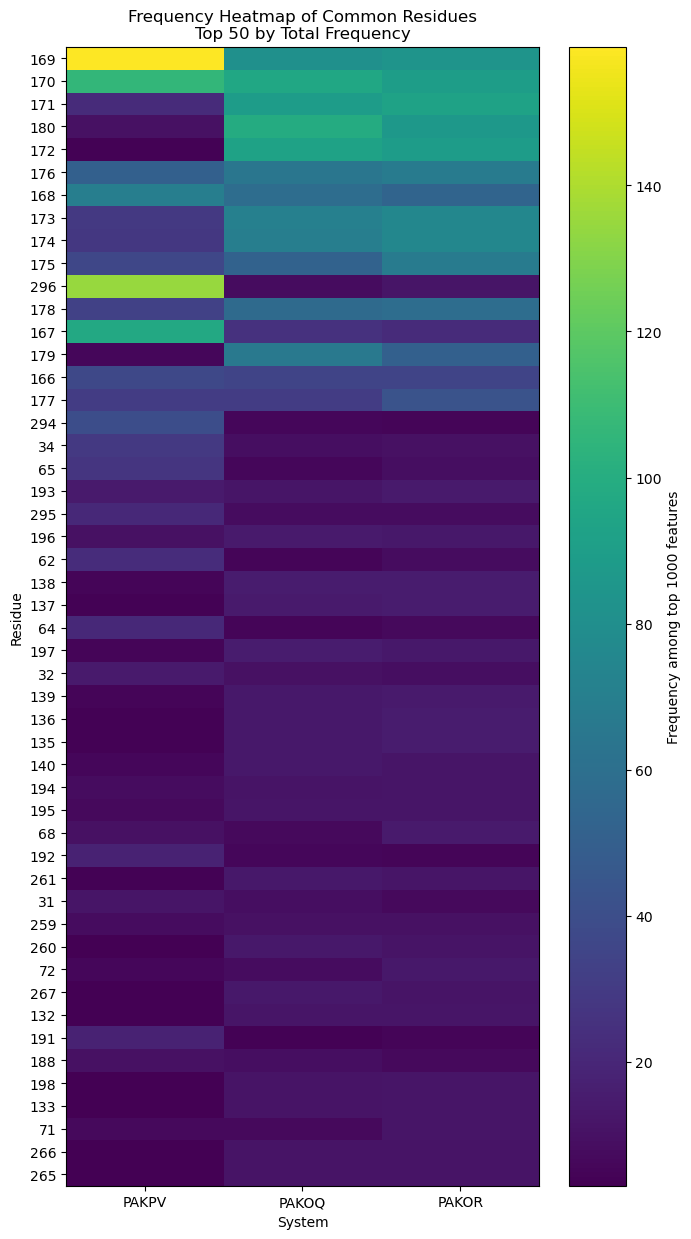

In [82]:
TOP_RESIDUES_FOR_HEATMAP = 50

heatmap_df = common_residue_comparison.head(
    TOP_RESIDUES_FOR_HEATMAP
).copy()

heatmap_matrix = heatmap_df[
    [
        "Frequency_PAKPV",
        "Frequency_PAKOQ",
        "Frequency_PAKOR"
    ]
].to_numpy()

fig, ax = plt.subplots(
    figsize=(7, max(8, TOP_RESIDUES_FOR_HEATMAP * 0.25))
)

image = ax.imshow(
    heatmap_matrix,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(3))
ax.set_xticklabels(SYSTEM_ORDER)

ax.set_yticks(np.arange(len(heatmap_df)))
ax.set_yticklabels(heatmap_df["Actual_Residue"])

ax.set_xlabel("System")
ax.set_ylabel("Residue")
ax.set_title(
    f"Frequency Heatmap of Common Residues\n"
    f"Top {TOP_RESIDUES_FOR_HEATMAP} by Total Frequency"
)

cbar = plt.colorbar(image, ax=ax)
cbar.set_label(f"Frequency among top {TOP_N} features")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "common_residue_frequency_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

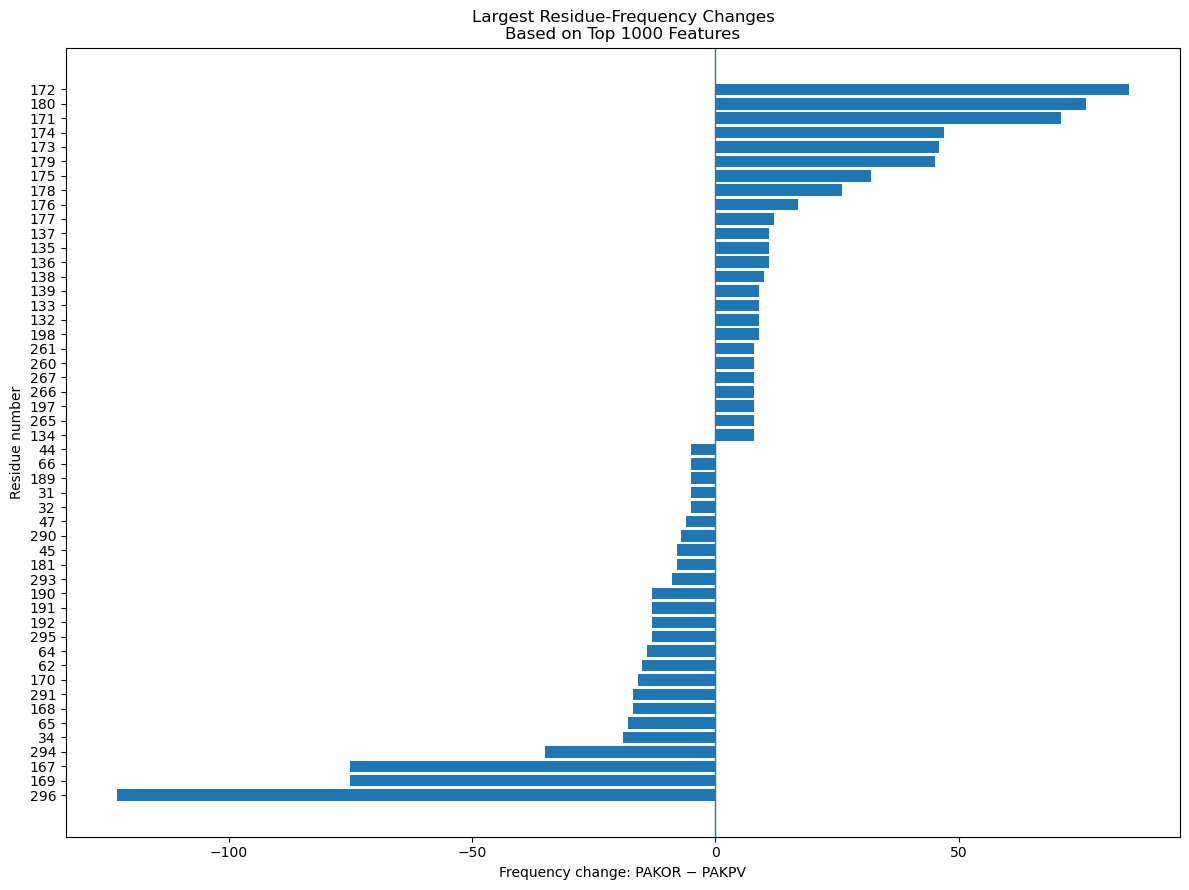

In [83]:
TOP_CHANGES = 25

change_df = common_residue_comparison.copy()

largest_increases = change_df.nlargest(
    TOP_CHANGES,
    "Overall_change_PAKOR_minus_PAKPV"
)

largest_decreases = change_df.nsmallest(
    TOP_CHANGES,
    "Overall_change_PAKOR_minus_PAKPV"
)

largest_changes = pd.concat(
    [largest_decreases, largest_increases],
    ignore_index=True
)

largest_changes = largest_changes.drop_duplicates(
    subset=["Actual_Residue"]
)

largest_changes = largest_changes.sort_values(
    "Overall_change_PAKOR_minus_PAKPV"
)

plt.figure(figsize=(12, 9))

plt.barh(
    largest_changes["Actual_Residue"].astype(str),
    largest_changes["Overall_change_PAKOR_minus_PAKPV"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Frequency change: PAKOR − PAKPV")
plt.ylabel("Residue number")

plt.title(
    f"Largest Residue-Frequency Changes\n"
    f"Based on Top {TOP_N} Features"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "largest_residue_frequency_changes_PAKOR_minus_PAKPV.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

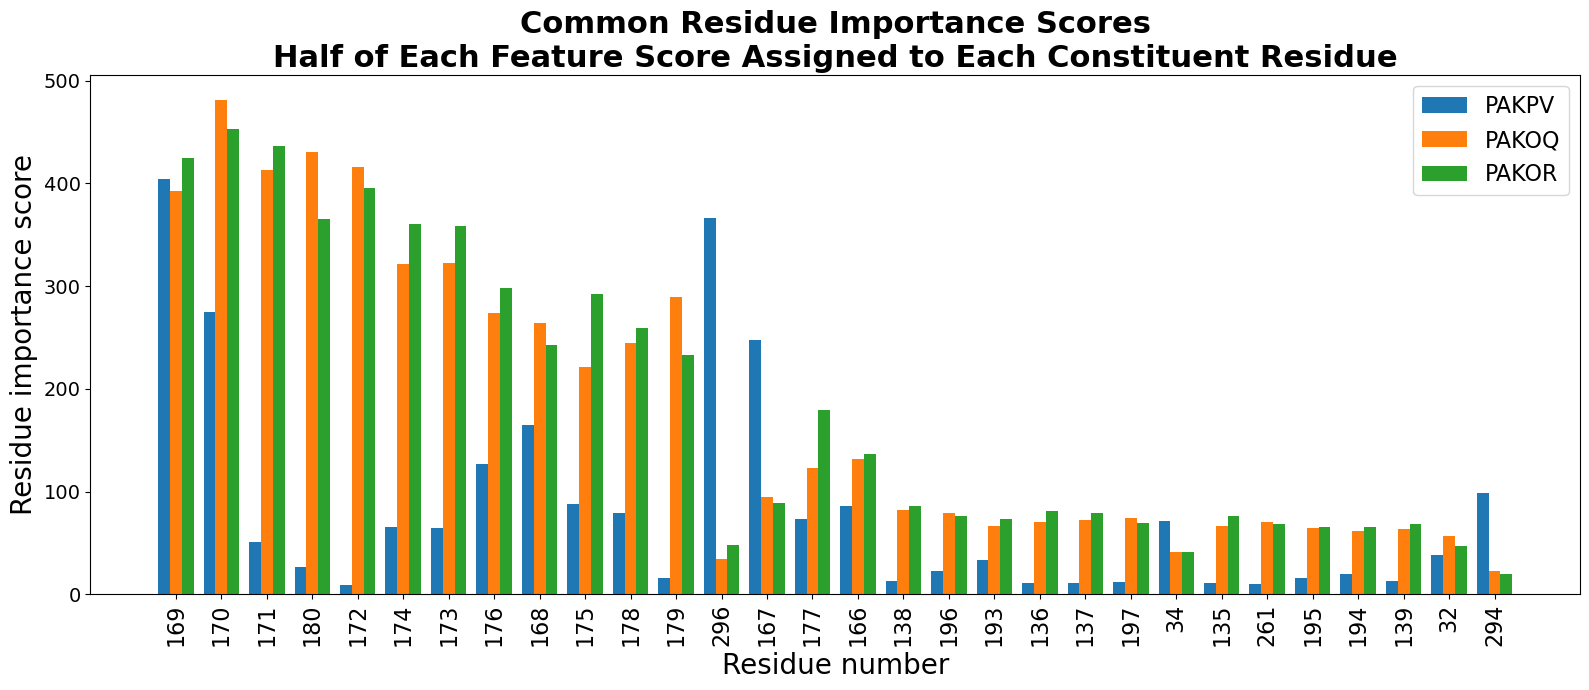

In [84]:
importance_plot_df = common_residue_comparison.copy()

importance_plot_df["Total_Half_Importance"] = (
    importance_plot_df["Half_Importance_Score_PAKPV"]
    + importance_plot_df["Half_Importance_Score_PAKOQ"]
    + importance_plot_df["Half_Importance_Score_PAKOR"]
)

importance_plot_df = importance_plot_df.sort_values(
    "Total_Half_Importance",
    ascending=False
).head(30)

x = np.arange(len(importance_plot_df))
bar_width = 0.26

plt.figure(figsize=(16, 7))

plt.bar(
    x - bar_width,
    importance_plot_df["Half_Importance_Score_PAKPV"],
    width=bar_width,
    label="PAKPV"
)

plt.bar(
    x,
    importance_plot_df["Half_Importance_Score_PAKOQ"],
    width=bar_width,
    label="PAKOQ"
)

plt.bar(
    x + bar_width,
    importance_plot_df["Half_Importance_Score_PAKOR"],
    width=bar_width,
    label="PAKOR"
)

# X-axis residue numbers
plt.xticks(
    x,
    importance_plot_df["Actual_Residue"],
    rotation=90,
    fontsize=16
)

# Y-axis numerical values
plt.yticks(fontsize=14)

# Axis labels
plt.xlabel(
    "Residue number",
    fontsize=20
)

plt.ylabel(
    "Residue importance score",
    fontsize=20
)

# Plot title
plt.title(
    "Common Residue Importance Scores\n"
    "Half of Each Feature Score Assigned to Each Constituent Residue",
    fontsize=22,
    fontweight="bold"
)

# Legend text
plt.legend(
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "common_residue_importance_grouped_bar.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

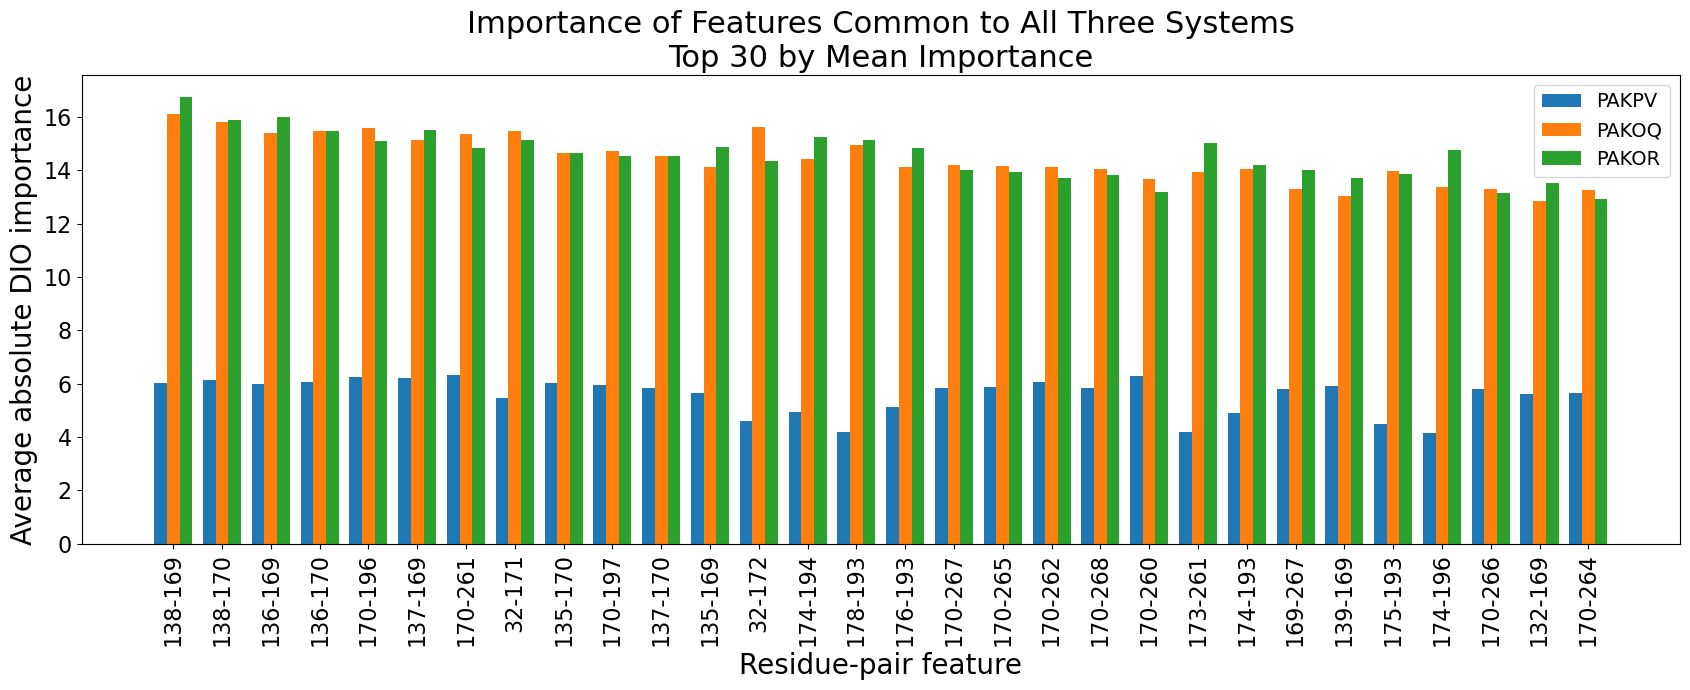

In [85]:
# ============================================================
# Compare importance scores of exact features common
# to all three systems
# ============================================================

TOP_COMMON_FEATURES_TO_PLOT = 30

# Select the top common features according to mean importance
feature_plot_df = common_feature_df.head(
    TOP_COMMON_FEATURES_TO_PLOT
).copy()

# X-axis positions
x = np.arange(len(feature_plot_df))

# Width of each bar
bar_width = 0.26

# Create figure
plt.figure(figsize=(17, 7))

# 4zlo bars
plt.bar(
    x - bar_width,
    feature_plot_df["Importance_PAKPV"],
    width=bar_width,
    label="PAKPV"
)

# 4zji bars
plt.bar(
    x,
    feature_plot_df["Importance_PAKOQ"],
    width=bar_width,
    label="PAKOQ"
)

# 4zjj bars
plt.bar(
    x + bar_width,
    feature_plot_df["Importance_PAKOR"],
    width=bar_width,
    label="PAKOR"
)

# X-axis labels
plt.xticks(
    ticks=x,
    labels=feature_plot_df["Actual_Feature"],
    rotation=90,
    fontsize=16
)

# Y-axis numerical values
plt.yticks(fontsize=16)

plt.xlabel(
    "Residue-pair feature",
    fontsize=20
)
plt.ylabel(
    "Average absolute DIO importance",
    fontsize=20
)

plt.title(
    "Importance of Features Common to All Three Systems\n"
    f"Top {TOP_COMMON_FEATURES_TO_PLOT} by Mean Importance",
    fontsize=22
)

plt.legend(
    fontsize=14
)
plt.tight_layout()

# Save figure
plt.savefig(
    OUTPUT_DIR / "common_top30_feature_importance_grouped_bar.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [86]:
feature_data["PAKPV"][
    [
        "Feature_ID",
        "DIO_Feature",
        "Actual_Feature",
        "DIO_Residue_1",
        "DIO_Residue_2",
        "Actual_Residue_1",
        "Actual_Residue_2"
    ]
].head(10)

,Feature_ID,DIO_Feature,Actual_Feature,DIO_Residue_1,DIO_Residue_2,Actual_Residue_1,Actual_Residue_2
0,400289,40-289,47-296,40,289,47,296
1,380289,38-289,45-296,38,289,45,296
2,1730289,173-289,180-296,173,289,180,296
3,390289,39-289,46-296,39,289,46,296
4,370289,37-289,44-296,37,289,44,296
5,360289,36-289,43-296,36,289,43,296
6,250289,25-289,32-296,25,289,32,296
7,1740289,174-289,181-296,174,289,181,296
8,250287,25-287,32-294,25,287,32,294
9,1570289,157-289,164-296,157,289,164,296


In [87]:
summary = pd.DataFrame({
    "Comparison": [
        "Features in PAKPV",
        "Features in PAKOQ",
        "Features in PAKOR",
        "Features common to all three",
        "Features unique to PAKPV",
        "Features unique to PAKOQ",
        "Features unique to PAKOR",
        "Features shared only by PAKPV and PAKOQ",
        "Features shared only by PAKPV and PAKOR",
        "Features shared only by PAKOQ and PAKOR",
        "Residues in PAKPV",
        "Residues in PAKOQ",
        "Residues in PAKOR",
        "Residues common to all three",
        "Residues unique to PAKPV",
        "Residues unique to PAKOQ",
        "Residues unique to PAKOR"
    ],
    "Count": [
        len(features_PAKPV),
        len(features_PAKOQ),
        len(features_PAKOR),
        len(common_features_all),
        len(unique_PAKPV),
        len(unique_PAKOQ),
        len(unique_PAKOR),
        len(only_PAKPV_PAKOQ),
        len(only_PAKPV_PAKOR),
        len(only_PAKOQ_PAKOR),
        len(residues_PAKPV),
        len(residues_PAKOQ),
        len(residues_PAKOR),
        len(common_residues_all),
        len(unique_residues_PAKPV),
        len(unique_residues_PAKOQ),
        len(unique_residues_PAKOR)
    ]
})

summary.to_csv(
    OUTPUT_DIR / f"overlap_summary_top{TOP_N}.csv",
    index=False
)

summary

,Comparison,Count
0,Features in PAKPV,1000
1,Features in PAKOQ,1000
2,Features in PAKOR,1000
3,Features common to all three,281
4,Features unique to PAKPV,675
5,Features unique to PAKOQ,114
6,Features unique to PAKOR,92
7,Features shared only by PAKPV and PAKOQ,11
8,Features shared only by PAKPV and PAKOR,33
9,Features shared only by PAKOQ and PAKOR,594


In [88]:
print("=" * 70)
print(f"TOP {TOP_N} FEATURE COMPARISON")
print("=" * 70)

print(
    f"\nExact residue-pair features common to all three systems: "
    f"{len(common_features_all)}"
)

print(
    f"Individual residues common to all three systems: "
    f"{len(common_residues_all)}"
)

print("\nCommon residues:")
print(sorted(common_residues_all))

print("\nResidues with strictly increasing frequency:")
print(strictly_increased["Actual_Residue"].tolist())

print("\nResidues with strictly decreasing frequency:")
print(strictly_decreased["Actual_Residue"].tolist())

print("\nAll results were saved in:")
print(OUTPUT_DIR.resolve())

TOP 1000 FEATURE COMPARISON

Exact residue-pair features common to all three systems: 281
Individual residues common to all three systems: 198

Common residues:
[8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 47, 49, 51, 52, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 102, 104, 107, 121, 122, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 147, 158, 159, 160, 161, 162, 163, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 204, 205, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 2